In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import random
import numpy as np

class CISB_Buffer:
    def __init__(self, capacity):
        self.initial_states = []  # Stores only s0
        self.trajectories = []    # Stores the full path (s0, s1, s2... st)
        self.capacity = capacity

    def add(self, trajectory):
        # trajectory is a list of states: [s0, s1, s2, ..., sT]
        if len(self.initial_states) >= self.capacity:
            self.initial_states.pop(0)
            self.trajectories.pop(0)
        
        self.initial_states.append(trajectory[0])
        self.trajectories.append(trajectory)

    def sample_batch(self, batch_size):
        indices = np.random.choice(len(self.initial_states), batch_size)
        
        s0_batch = []
        pos_goal_batch = []
        neg_goal_batch = []

        for idx in indices:
            traj = self.trajectories[idx]
            # Positive: Pick a random state that happened later in THIS trajectory
            t = random.randint(1, len(traj) - 1)
            
            s0_batch.append(traj[0])
            pos_goal_batch.append(traj[t])
            
            # Negative: Pick a state from a COMPLETELY DIFFERENT trajectory
            random_idx = (idx + random.randint(1, len(self.trajectories)-1)) % len(self.trajectories)
            neg_traj = self.trajectories[random_idx]
            random_t = random.randint(0, len(neg_traj) - 1)
            neg_goal_batch.append(neg_traj[random_t])

        return (torch.FloatTensor(np.array(s0_batch)), 
                torch.FloatTensor(np.array(pos_goal_batch)), 
                torch.FloatTensor(np.array(neg_goal_batch)))
    
class ContrastiveNet(nn.Module):
    def __init__(self, state_dim):
        super().__init__()
        # A simple neural network to "encode" states
        self.encoder = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64) # The output is the "embedding"
        )

    def forward(self, start_state, goal_state):
        z_start = self.encoder(start_state)
        z_goal = self.encoder(goal_state)
        
        # Calculate the dot product (similarity score)
        # Higher score = Model thinks this goal is reachable from this start
        score = torch.sum(z_start * z_goal, dim=-1)
        return score
    
def train_step(model, buffer, optimizer, batch_size=32):
    s0, s_pos, s_neg = buffer.sample_batch(batch_size)

    # Get scores for the real pairs and the fake pairs
    pos_scores = model(s0, s_pos)
    neg_scores = model(s0, s_neg)

    # InfoNCE Loss / Contrastive Loss:
    # We want pos_scores to be high and neg_scores to be low.
    # A common way is to treat this as a classification problem:
    # "Which of these two is the real one?"
    
    logits = torch.cat([pos_scores.unsqueeze(1), neg_scores.unsqueeze(1)], dim=1)
    labels = torch.zeros(batch_size, dtype=torch.long) # Index 0 is always the 'pos'
    
    loss = nn.CrossEntropyLoss()(logits, labels)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    return loss.item()

Training...
Epoch 0, Loss: 0.5566
Epoch 200, Loss: 0.4631
Epoch 400, Loss: 0.4629
Epoch 600, Loss: 0.5352
Epoch 800, Loss: 0.5200
Epoch 1000, Loss: 0.3957


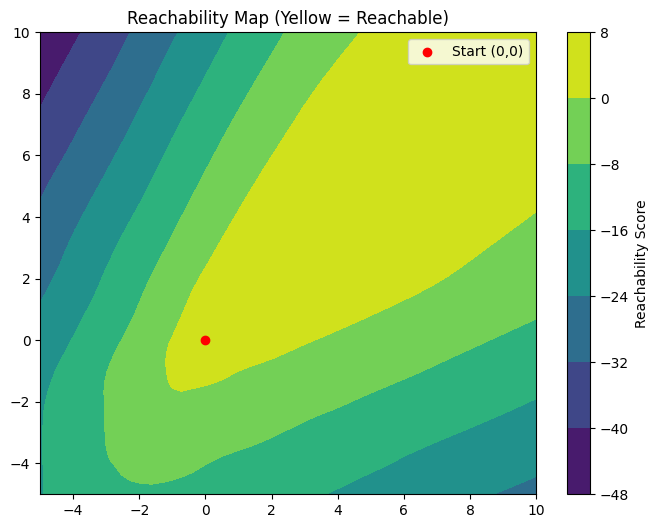

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import random
import numpy as np
import matplotlib.pyplot as plt

# --- 1. CISB Buffer Implementation ---
class CISB_Buffer:
    def __init__(self, capacity):
        self.initial_states = []
        self.trajectories = []
        self.capacity = capacity

    def add(self, trajectory):
        if len(self.initial_states) >= self.capacity:
            self.initial_states.pop(0)
            self.trajectories.pop(0)
        self.initial_states.append(trajectory[0])
        self.trajectories.append(trajectory)

    def sample_batch(self, batch_size):
        indices = np.random.choice(len(self.initial_states), batch_size)
        s0_batch, pos_goal_batch, neg_goal_batch = [], [], []

        for idx in indices:
            traj = self.trajectories[idx]
            t = random.randint(1, len(traj) - 1)
            s0_batch.append(traj[0])
            pos_goal_batch.append(traj[t])
            
            random_idx = (idx + random.randint(1, len(self.trajectories)-1)) % len(self.trajectories)
            neg_traj = self.trajectories[random_idx]
            random_t = random.randint(0, len(neg_traj) - 1)
            neg_goal_batch.append(neg_traj[random_t])

        return (torch.FloatTensor(np.array(s0_batch)), 
                torch.FloatTensor(np.array(pos_goal_batch)), 
                torch.FloatTensor(np.array(neg_goal_batch)))

# --- 2. Contrastive Model ---
class ContrastiveNet(nn.Module):
    def __init__(self, state_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64)
        )

    def forward(self, start_state, goal_state):
        z_start = self.encoder(start_state)
        z_goal = self.encoder(goal_state)
        return torch.sum(z_start * z_goal, dim=-1)

# --- 3. Training Function ---
def train_step(model, buffer, optimizer, batch_size=32):
    s0, s_pos, s_neg = buffer.sample_batch(batch_size)
    pos_scores = model(s0, s_pos)
    neg_scores = model(s0, s_neg)
    
    logits = torch.cat([pos_scores.unsqueeze(1), neg_scores.unsqueeze(1)], dim=1)
    labels = torch.zeros(batch_size, dtype=torch.long)
    
    loss = nn.CrossEntropyLoss()(logits, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return loss.item()

# --- 4. Simulation and Test ---
def simulate_trajectories(num_episodes=500, horizon=20):
    buffer = CISB_Buffer(capacity=num_episodes)
    for _ in range(num_episodes):
        current_state = np.array([random.uniform(-1, 1), random.uniform(-1, 1)])
        traj = [current_state.copy()]
        for _ in range(horizon):
            # Agent moves North-East (Positive X, Positive Y)
            step = np.array([random.uniform(-0.1, 0.5), random.uniform(-0.1, 0.5)])
            current_state += step
            traj.append(current_state.copy())
        buffer.add(traj)
    return buffer

# Execution
state_dim = 2
model = ContrastiveNet(state_dim)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
buffer = simulate_trajectories()

print("Training...")
for epoch in range(1001):
    loss = train_step(model, buffer, optimizer, batch_size=64)
    if epoch % 200 == 0:
        print(f"Epoch {epoch}, Loss: {loss:.4f}")

# Visualization
model.eval()
start_point = torch.FloatTensor([[0.0, 0.0]])
x, y = np.linspace(-5, 10, 50), np.linspace(-5, 10, 50)
X, Y = np.meshgrid(x, y)
grid_points = torch.FloatTensor(np.stack([X.ravel(), Y.ravel()], axis=1))
with torch.no_grad():
    scores = model(start_point.repeat(len(grid_points), 1), grid_points).numpy()

plt.figure(figsize=(8, 6))
plt.contourf(X, Y, scores.reshape(X.shape), cmap='viridis')
plt.colorbar(label='Reachability Score')
plt.scatter([0], [0], color='red', label='Start (0,0)')
plt.title("Reachability Map (Yellow = Reachable)")
plt.legend()
plt.show()